# CI-05 · left CSV → текущий драйвер → графики слежения

Подвод и CSV выполняются **двумя отдельными** `FollowJointTrajectory`; драйвер интерполирует их и
отправляет ServoJ. Ноутбук не вызывает SDK, не опрашивает робота вторым соединением
и не меняет параметры ноды. `actual` — измеренные углы из action-feedback.
CSV-цель содержит только `positions + time_from_start`; между узлами — линейная
интерполяция. Столбцы скоростей/ускорений не читаются и не отправляются.

**Нужна новая сборка драйвера с trajectory_timing.**
После обновления проекта пересоберите образ или workspace и перезапустите launch.

**Запуск драйвера (отдельный терминал, ROS Humble):**
```bash
source /opt/ros/humble/setup.bash
source ros2_ws/install/setup.bash  # из корня iimt_manipulation; в Docker уже подключено
ros2 launch iimt_ros2_moveit_config iimt_driver_moveit.launch.py \
  use_mock_hardware:=true enable_motion:=true launch_rviz:=false \
  command_rate:=125.0 read_rate:=125.0 trajectory_advance_ms:=0.0
```
Это запуск **без робота**. Реальные IP и упреждения задавайте только после проверки стенда; см. README проекта. Значение 330 мс не универсально.
В обоих случаях нужна строка `enable_motion:=true`, иначе action отвергается.
Перед `Run All` установите `RUN_APPROACH=False`, `RUN_MOTION=False`, чтобы не отправлять движения.
Ядро Jupyter: Python 3.10 с ROS-окружением; нужны `numpy`, `pandas`, `matplotlib`.
Запускайте Jupyter из терминала после тех же `source`, что и launch.

**Важно:** убедитесь, что CSV описывает именно подключённую руку. Подвод выполняется
в суставном пространстве **без проверки столкновений**. Освободите рабочую зону,
держите аппаратный E-stop доступным. Не запускайте второй SDK-клиент или другую цель
из RViz одновременно. Программная отмена не заменяет аппаратную остановку.

## 1. CSV и время
Читаются только `t` и `left_q1_rad…left_q6_rad`. Остальные столбцы не нужны.
`TIME_SCALE` умножает времена файла: например, 1.5 превращает 4 секунды в 6 секунд.
`TIME_SCALE=1` — исходные времена, без автоматического ретайминга. Позиции не меняются.
В данном CSV линейная скорость J1 немного превышает текущий лимит 1 рад/с при
масштабе 1; предпросмотр это покажет и заблокирует отправку. Лимиты не отключаются.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data" / "trajectory_both_TimeGrid_30Hz.csv").is_file()
             and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Запустите Jupyter из корня iimt_manipulation или его notebooks/")
CSV = ROOT / "data" / "trajectory_both_TimeGrid_30Hz.csv"   # Нужны только t и left_q1_rad…left_q6_rad.
TIME_SCALE = 1.5       # Масштаб времени: t*s. 1.0 = исходное время.
START_DELAY_S = 3.0    # Старт через 3 s от формирования сообщения: trajectory.header.stamp. 0 = сразу.
APPROACH_S = 12.0      # Отдельный подвод к q[0] с остановкой.
JOINTS = ["shoulder_joint", "upper_arm_joint", "forearm_joint",
          "wrist_1_joint", "wrist_2_joint", "wrist_3_joint"]
CONTROLLER = "iimt_group_controller"
DRIVER_NODE = "/iimt_ros2_driver"

loaded = approach_prepared = prepared = None

/opt/iimt/venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
loaded = approach_prepared = prepared = None  # Не использовать прежний путь после неудачного чтения.
columns = ["t", *[f"left_q{j}_rad" for j in range(1, 7)]]
source = pd.read_csv(CSV, usecols=columns)[columns]
data = source.to_numpy(dtype=float)
if (len(data) < 2 or not np.isfinite(data).all() or np.any(np.diff(data[:, 0]) <= 0)
        or not np.isfinite(TIME_SCALE) or TIME_SCALE < 1):
    raise ValueError("Нужны конечные данные, возрастающее t и TIME_SCALE >= 1")
t = (data[:, 0] - data[0, 0]) * TIME_SCALE
q = data[:, 1:7]
print(f"left: {len(t)} точек, CSV {data[-1, 0]-data[0, 0]:.6f} s → задание {t[-1]:.6f} s")
display(source.head(3))
loaded = {"source": str(CSV), "scale": float(TIME_SCALE)}

left: 121 точек, CSV 4.000000 s → задание 6.000000 s


,t,left_q1_rad,left_q2_rad,left_q3_rad,left_q4_rad,left_q5_rad,left_q6_rad
0,0.000000,0.000000,-1.570796,0.000000,-1.570796,0.000000,0.000000
1,0.033333,-0.034898,-1.570305,-0.003351,-1.543496,0.031203,0.000358
2,0.066667,-0.069795,-1.569814,-0.006702,-1.516197,0.062406,0.000717


## 2. Подключение
Читаем `/joint_states` и параметры запущенной ноды. Ничего не меняем. После опыта
выполните последнюю ячейку; не создавайте второй ROS-клиент поверх первого.

In [3]:
import rclpy
from rclpy.context import Context
from rclpy.duration import Duration as RosDuration
from rclpy.executors import SingleThreadedExecutor
from rclpy.action import ActionClient
from rclpy.qos import qos_profile_sensor_data, QoSProfile, DurabilityPolicy, ReliabilityPolicy
from diagnostic_msgs.msg import DiagnosticArray
from control_msgs.action import FollowJointTrajectory
from rcl_interfaces.srv import GetParameters
from sensor_msgs.msg import JointState
from trajectory_msgs.msg import JointTrajectoryPoint
from builtin_interfaces.msg import Duration

if globals().get("node") is not None:
    raise RuntimeError("ROS-клиент уже создан: сначала выполните отключение")
ctx = Context()
rclpy.init(context=ctx)
node = rclpy.create_node("iimt_left_csv_ethernet", context=ctx)
executor = SingleThreadedExecutor(context=ctx)
executor.add_node(node)
client = ActionClient(node, FollowJointTrajectory, f"/{CONTROLLER}/follow_joint_trajectory")
joint_samples = []
pending = None
timing_by_goal = {}

def outstanding():
    if pending is None or pending.get("rejected", False):
        return False
    future = pending.get("result")
    if future is None or not future.done():
        return True
    try:
        return future.result().status not in (4, 5, 6)  # SUCCEEDED / CANCELED / ABORTED
    except Exception:
        return True  # Завершение future с ошибкой — не подтверждение остановки goal.


def ns(stamp):
    return stamp.sec * 10**9 + stamp.nanosec

def collect(seconds):
    deadline = time.monotonic() + seconds
    while time.monotonic() < deadline:
        executor.spin_once(timeout_sec=min(.02, max(0., deadline-time.monotonic())))

def until(predicate, timeout):
    deadline = time.monotonic() + timeout
    while not predicate() and time.monotonic() < deadline:
        executor.spin_once(timeout_sec=.02)
    if not predicate():
        raise TimeoutError("ROS-запрос не завершился")

def wait(future, timeout):
    until(future.done, timeout)
    return future.result()

def call(kind, name, request=None):
    service = node.create_client(kind, name)
    try:
        if not service.wait_for_service(timeout_sec=5):
            raise RuntimeError(f"Нет {name}: проверьте launch/source/ROS_DOMAIN_ID")
        return wait(service.call_async(request if request is not None else kind.Request()), 5)
    finally:
        node.destroy_client(service)

def on_joints(msg):
    if set(JOINTS).issubset(msg.name) and len(msg.position) == len(msg.name):
        values = np.array([msg.position[msg.name.index(j)] for j in JOINTS])
        if np.isfinite(values).all():
            joint_samples.append((ns(msg.header.stamp), values))
            del joint_samples[:-100]

subscription = node.create_subscription(JointState, "/joint_states", on_joints, qos_profile_sensor_data)

def on_timing(msg):
    for status in msg.status:
        if status.name != "trajectory_timing":
            continue
        values = {kv.key: kv.value for kv in status.values}
        try:
            timing = {k: int(values[k]) for k in
                      ("receipt_stamp_ns", "nominal_start_stamp_ns", "first_command_stamp_ns")}
            timing["nominal_start_final"] = values["nominal_start_final"] == "true"
            uuid = values["goal_uuid"]
        except (KeyError, ValueError):
            continue
        timing_by_goal[uuid] = timing
        if len(timing_by_goal) > 16:
            timing_by_goal.pop(next(iter(timing_by_goal)))
        if pending is not None and pending["record"].get("goal_uuid") == uuid:
            pending["record"]["timing"] = timing

timing_subscription = node.create_subscription(DiagnosticArray, DRIVER_NODE+"/trajectory_timing", on_timing,
    QoSProfile(depth=1, reliability=ReliabilityPolicy.RELIABLE, durability=DurabilityPolicy.TRANSIENT_LOCAL))

def driver_parameters():
    names = ["enable_motion", "use_mock_hardware", "command_rate", "read_rate",
             "robot_ip", "feedback_transport", "read_timeout", "state_timeout",
             "trajectory_advance_ms", "servo.period", "servo.a", "servo.v", "servo.lookahead_time", "servo.gain",
             "path_tolerance", "goal_tolerance", "goal_time_tolerance",
             *["limits."+key for key in ("min_position", "max_position", "max_velocity", "max_acceleration", "max_step")]]
    values = call(GetParameters, DRIVER_NODE+"/get_parameters",
                  GetParameters.Request(names=names)).values
    if [v.type for v in values] != [1, 1, 3, 3, 4, 4, 3, 3] + [3]*9 + [8]*5:
        raise RuntimeError("Нужна новая сборка iimt_ros2_driver с trajectory_timing; перезапустите launch")
    fields = {1: "bool_value", 3: "double_value", 4: "string_value", 8: "double_array_value"}
    return dict(zip(names, [list(v.double_array_value) if v.type == 8 else getattr(v, fields[v.type])
                            for v in values]))

def stationary_pose():
    rate = float(driver["read_rate"])
    if not np.isfinite(rate) or rate <= 0:
        raise RuntimeError("Некорректный read_rate")
    collect(max(.4, 4/rate))
    now = node.get_clock().now().nanoseconds
    fresh = [(stamp, values) for stamp, values in joint_samples
             if 0 <= (now-stamp)*1e-9 <= max(.3, 3.5/rate)]
    if (len(fresh) < 3 or (now-fresh[-1][0])*1e-9 > driver["state_timeout"]
            or np.max(np.ptp([v for _, v in fresh], axis=0)) > .002):
        raise RuntimeError("Нет свежей неподвижной позы; проверьте /joint_states и read_rate")
    return fresh[-1][1].copy()

driver = driver_parameters()
print("MOCK — не измерение физического робота" if driver["use_mock_hardware"] else "РЕАЛЬНЫЙ РОБОТ: "+driver["robot_ip"])
print({k: driver[k] for k in ("enable_motion", "feedback_transport", "command_rate", "read_rate", "read_timeout", "trajectory_advance_ms")})
display(pd.Series(stationary_pose(), index=JOINTS, name="measured_rad"))

MOCK — не измерение физического робота
{'enable_motion': True, 'feedback_transport': 'tcp', 'command_rate': 125.0, 'read_rate': 125.0, 'read_timeout': 0.1, 'trajectory_advance_ms': 0.0}


shoulder_joint     0.0
upper_arm_joint    0.0
forearm_joint      0.0
wrist_1_joint      0.0
wrist_2_joint      0.0
wrist_3_joint      0.0
Name: measured_rad, dtype: float64

## 3. Подвод к первой точке CSV — отдельно
Общие функции ниже только определяются, движения нет. Обе цели используют одни
и те же проверки/отмену. Плотная сетка используется только для предпросмотра подвода. Для CSV
показываются исходные углы, без расчёта dq/ddq и добавления точек. Столкновения не проверяются. Жёсткие проверки драйвера включены.

In [4]:
def prepare_path(path_t, path_q, path_v, path_a, lead, label):
    if loaded is None or loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
        raise RuntimeError("Настройки CSV изменились: повторите чтение файла")
    if (not np.isfinite(path_t).all() or path_t[0] != 0
            or np.any(np.diff(np.rint(path_t*1e9).astype(np.int64)) <= 0)):
        raise ValueError("Нужны положительные длительности и различные ROS-времена")
    positions_only = path_v is None and path_a is None
    values = path_q if positions_only else np.c_[path_q, path_v, path_a]
    if not np.isfinite(values).all():
        raise ValueError("Неконечные значения траектории")
    limits = {k: np.array(driver["limits."+k]) for k in
              ("min_position", "max_position", "max_velocity", "max_acceleration", "max_step")}
    if any(x.shape != (6,) or not np.isfinite(x).all() for x in limits.values()):
        raise ValueError("Некорректные limits.* драйвера")
    h = np.diff(path_t)[:, None]
    delta = np.diff(path_q, axis=0)
    if positions_only:
        # Точное задание для линейных сегментов: экстремумы q — в узлах.
        grid, qg = path_t, path_q
        # Только проверка допустимого перемещения за dt; dq/ddq и новые узлы не создаются.
        rate = driver["command_rate"]
        if not np.isfinite(rate) or rate <= 0:
            raise ValueError("Некорректный command_rate")
        limits_ok = bool(np.all(qg >= limits["min_position"]) and np.all(qg <= limits["max_position"])
            and np.all(abs(delta) <= limits["max_velocity"] * h)
            and np.all(abs(delta) <= limits["max_step"] * rate * h))
        display(pd.DataFrame({"joint": JOINTS, "min_q": np.min(path_q, axis=0),
            "max_q": np.max(path_q, axis=0), "limit_min_q": limits["min_position"],
            "limit_max_q": limits["max_position"]}))
    else:
        # Те же квинтические границы q/dq/ddq, что у текущего драйвера.
        coef = np.stack([path_q[:-1], h*path_v[:-1], h*h*path_a[:-1]/2,
            10*delta-h*(6*path_v[:-1]+4*path_v[1:])-h*h*(1.5*path_a[:-1]-.5*path_a[1:]),
            -15*delta+h*(8*path_v[:-1]+7*path_v[1:])+h*h*(1.5*path_a[:-1]-path_a[1:]),
            6*delta-3*h*(path_v[:-1]+path_v[1:])-.5*h*h*(path_a[:-1]-path_a[1:])], axis=-1)
        grid = np.unique(np.concatenate([np.linspace(a, b, 101) for a, b in zip(path_t[:-1], path_t[1:])]))
        index = np.clip(np.searchsorted(path_t, grid, side="right")-1, 0, len(h)-1)
        u = ((grid-path_t[index])/h[index, 0])[:, None, None]
        factors = (np.ones(6), np.arange(1, 6), np.arange(2, 6)*np.arange(1, 5))
        qg, vg, ag = [np.sum(coef[index, :, d:]*factors[d]*u**np.arange(6-d), axis=-1)/h[index]**d
                      for d in range(3)]
        rate = driver["command_rate"]
        if not np.isfinite(rate) or rate <= 0:
            raise ValueError("Некорректный command_rate")
        limits_ok = bool(np.all(qg >= limits["min_position"]) and np.all(qg <= limits["max_position"])
            and np.all(np.max(abs(vg), axis=0) <= limits["max_velocity"])
            and np.all(np.max(abs(ag), axis=0) <= limits["max_acceleration"])
            and np.all(np.max(abs(vg), axis=0)/rate <= limits["max_step"]))
        display(pd.DataFrame({"joint": JOINTS, "peak_v": np.max(abs(vg), axis=0),
            "limit_v": limits["max_velocity"], "peak_a": np.max(abs(ag), axis=0),
            "limit_a": limits["max_acceleration"]}))
    print(label, f"{path_t[-1]:.2f} s; лимиты:", "OK" if limits_ok else "FAIL — отправка заблокирована")
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(grid-lead, qg)
    if label == "CSV": ax.axvspan(0, t[-1], color="gray", alpha=.12)
    ax.set(title=label, xlabel="Время от начала участка, s", ylabel="Задано, rad")
    ax.legend([f"J{j}" for j in range(1, 7)], ncol=6); ax.grid(True); plt.tight_layout()
    return {"driver": driver.copy(), "t": path_t.copy(), "q": path_q.copy(),
        "v": None if positions_only else path_v.copy(), "a": None if positions_only else path_a.copy(), "csv_t": t.copy(), "csv_q": q.copy(),
        "lead": float(lead), "scale": float(TIME_SCALE), "source": str(CSV),
        "limits_ok": limits_ok, "joints": JOINTS.copy(), "label": label,
        "interpolation": "linear" if positions_only else "quintic"}

def cancel():
    if pending is not None:
        pending["cancel"] = True
        handle = pending.get("handle")
        if handle is not None and handle.accepted:
            handle.cancel_goal_async()
        collect(3.)
    print("Отмена запрошена; terminal:", not outstanding(), "— это НЕ аппаратный E-stop")

def accepted(future):
    handle = future.result()
    pending["handle"] = handle
    if not handle.accepted:
        pending["rejected"] = True
    else:
        pending["record"]["goal_uuid"] = bytes(handle.goal_id.uuid).hex()
        pending["record"]["timing"] = timing_by_goal.get(pending["record"]["goal_uuid"])
        pending["result"] = handle.get_result_async()
        if pending["cancel"]:
            handle.cancel_goal_async()

def on_feedback(message):
    handle = pending.get("handle") if pending is not None else None
    if handle is None or list(message.goal_id.uuid) != list(handle.goal_id.uuid):
        return
    f = message.feedback
    if len(f.joint_names) != 6 or set(f.joint_names) != set(JOINTS):
        return
    if len(f.desired.positions) != 6 or len(f.actual.positions) != 6:
        return
    order = [f.joint_names.index(j) for j in JOINTS]
    pending["record"]["rows"].append([ns(f.header.stamp), node.get_clock().now().nanoseconds,
                 ns(f.desired.time_from_start)*1e-9,
                 *[f.desired.positions[j] for j in order], *[f.actual.positions[j] for j in order]])


def execute_path(plan, record):
    global pending
    if outstanding():
        raise RuntimeError("Предыдущая цель не завершена: сначала cancel() и подтверждение остановки")
    if plan is None:
        raise RuntimeError("Нет успешного предпросмотра: выполните загрузку и подготовку")
    if plan["joints"] != JOINTS or plan["source"] != str(CSV) or plan["scale"] != TIME_SCALE:
        raise RuntimeError("Настройки изменились после предпросмотра: подготовьте путь заново")
    current_driver = driver_parameters()
    if current_driver != plan["driver"]:
        raise RuntimeError("Параметры драйвера изменились: повторите предпросмотр")
    if not np.isfinite(START_DELAY_S) or START_DELAY_S < 0:
        raise ValueError("START_DELAY_S должен быть конечным и неотрицательным")
    if 0 < START_DELAY_S <= current_driver["trajectory_advance_ms"]*.001:
        raise ValueError("START_DELAY_S должен превышать упреждение и оставлять запас на доставку цели")
    if not current_driver["enable_motion"]:
        raise RuntimeError("Выполнение целей выключено: enable_motion=false (включая mock)")
    if not plan["limits_ok"]:
        raise RuntimeError("Предпросмотр не прошёл лимиты")
    if np.max(abs(stationary_pose()-plan["q"][0])) > .005:
        raise RuntimeError("Стартовая поза изменилась: повторите предпросмотр")
    if not client.wait_for_server(timeout_sec=5):
        raise RuntimeError("Нет FollowJointTrajectory сервера")
    goal = FollowJointTrajectory.Goal()
    goal.trajectory.joint_names = JOINTS
    for i, ti in enumerate(plan["t"]):
        seconds, nanos = divmod(round(float(ti)*1e9), 10**9)
        point = JointTrajectoryPoint(positions=plan["q"][i].tolist(),
                                    time_from_start=Duration(sec=seconds, nanosec=nanos))
        if plan["v"] is not None: point.velocities = plan["v"][i].tolist()
        if plan["a"] is not None: point.accelerations = plan["a"][i].tolist()
        goal.trajectory.points.append(point)
    # Назначаем абсолютное время ПОСЛЕ подготовки точек, непосредственно перед отправкой.
    request_time = node.get_clock().now()
    if START_DELAY_S > 0:
        goal.trajectory.header.stamp = (request_time + RosDuration(seconds=float(START_DELAY_S))).to_msg()
    record.clear()
    record.update({**plan, "run_id": time.monotonic_ns(), "request_stamp_ns": request_time.nanoseconds, "requested_start_stamp_ns": ns(goal.trajectory.header.stamp), "start_delay_s": float(START_DELAY_S), "status": None, "error_code": None, "error_string": "", "rows": []})
    pending = {"cancel": False, "record": record}
    sent_at = time.monotonic()
    try:
        pending["send"] = client.send_goal_async(goal, feedback_callback=on_feedback)
        pending["send"].add_done_callback(accepted)
        wait(pending["send"], 5)
        until(lambda: "handle" in pending, 5)  # Ответ и его callback могут исполняться отдельно.
        if pending.get("rejected"):
            raise RuntimeError("Контроллер отверг цель")
        result = wait(pending["result"], float(record["t"][-1])+max(record["start_delay_s"], current_driver["trajectory_advance_ms"]*.001)+current_driver["goal_time_tolerance"]+5)
        record.update(status=result.status, error_code=result.result.error_code,
                   error_string=result.result.error_string,
                   action_roundtrip_s=time.monotonic()-sent_at)
        collect(.4)
        print({k: record[k] for k in ("status", "error_code", "action_roundtrip_s")})
        if result.status != 4 or result.result.error_code != 0:
            raise RuntimeError(f"Выполнение прервано: {result.result.error_string}")
    except BaseException:
        cancel()
        raise
    finally:
        if record.get("timing"):
            print("Серверные timestamps:", record["timing"])
        print(f"В памяти {len(record['rows'])} goal-feedback измерений. Графики доступны и после отказа.")

### Предпросмотр подвода
От текущей неподвижной позы до `q[0]` за `APPROACH_S`. В начале и конце скорость и
ускорение нулевые. Проверьте весь путь и свободное пространство.

,joint,peak_v,limit_v,peak_a,limit_a
0,shoulder_joint,0.0,3.1415,0.0,1.875
1,upper_arm_joint,0.0,3.1415,0.0,2.500
2,forearm_joint,0.0,3.1415,0.0,3.750
3,wrist_1_joint,0.0,3.1415,0.0,3.125
4,wrist_2_joint,0.0,3.1415,0.0,3.750
5,wrist_3_joint,0.0,3.1415,0.0,3.750


Подвод к q[0] 12.00 s; лимиты: OK


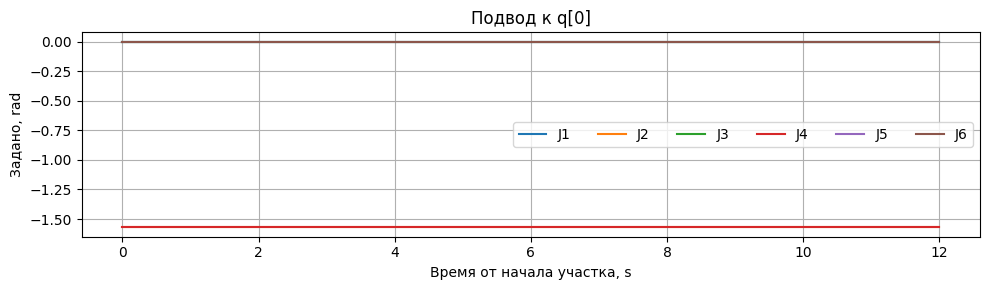

In [8]:
approach_prepared = None
if outstanding():
    raise RuntimeError("Сначала дождитесь завершения предыдущей цели")
if loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
    raise RuntimeError("Повторите загрузку CSV")
if not np.isfinite(APPROACH_S) or APPROACH_S <= 0:
    raise ValueError("APPROACH_S должен быть положительным")
driver = driver_parameters()
start_q = stationary_pose()
approach_prepared = prepare_path(np.array([0., APPROACH_S]), np.vstack([start_q, q[0]]),
                                 np.zeros((2, 6)), np.zeros((2, 6)), 0., "Подвод к q[0]")

### Выполнить только подвод
Поставьте `RUN_APPROACH=True` в следующей ячейке. Она ждёт завершения цели и
проверяет неподвижную позу; CSV автоматически **не** запускается.
Прерывание запрашивает отмену; `cancel()` доступен повторно. Это не аппаратный E-stop.

In [9]:
RUN_APPROACH = True  # Разрешите одну попытку после проверки подвода.
if not RUN_APPROACH:
    print("RUN_APPROACH=False: подвод не отправлен")
else:
    RUN_APPROACH = False
    if outstanding():
        raise RuntimeError("Предыдущая цель ещё активна/неизвестна: сначала cancel()")
    prepared = None  # CSV надо заново подготовить из достигнутой позы.
    approach_run = {}
    execute_path(approach_prepared, approach_run)
    reached = stationary_pose()
    if np.max(abs(reached-approach_run["q"][-1])) > .005:
        raise RuntimeError("Начальная поза не достигнута/не удерживается")
    print("Подвод завершён: робот остановлен у первой точки CSV. CSV НЕ запускался.")

{'status': 4, 'error_code': 0, 'action_roundtrip_s': 15.006355146000715}
Серверные timestamps: {'receipt_stamp_ns': 1793290300635578691, 'nominal_start_stamp_ns': 1793290303634572392, 'first_command_stamp_ns': 1793290303640260967, 'nominal_start_final': True}
В памяти 1501 goal-feedback измерений. Графики доступны и после отказа.
Подвод завершён: робот остановлен у первой точки CSV. CSV НЕ запускался.


## 4. Подготовка только CSV
Никаких дополнительных узлов до или после файла. Нет разгона, тормозного участка
внутри CSV. Номинальный старт назначается через **START_DELAY_S секунд от формирования сообщения ноутбуком**
в `trajectory.header.stamp`. Задержка задаётся отдельно для каждой цели, без параметра ноды.
Если робот не стоит в первой точке — выполните
отдельный подвод. Цель отправляет только `q` и времена узлов; драйвер линейно
интерполирует положения и удерживает последнюю позицию после конца.

**Упреждение:** параметр launch `trajectory_advance_ms` (по умолчанию 0).
Для опыта 20261027T005533 оценка эффективного отставания — около 330 мс; это
экспериментальное значение, не гарантия и не доказательство задержки только привода.
При `START_DELAY_S=3` и упреждении 330 мс номинальный t=0 наступает
через 3 s от формирования сообщения; ServoJ начинает отправляться примерно через 2.67 s
(с точностью до такта). То есть 3 s относятся к эталонной/ожидаемой реальной
траектории, а не к первой опережающей команде. Точки/производные не добавляются.
Командная выборка опережает номинальное время; графики и ошибки НЕ сдвигаются.
`START_DELAY_S=0` оставляет нулевой header для немедленного старта.
Положительная задержка должна превышать упреждение и оставлять запас на передачу.
Упреждение не равно `servo.lookahead_time`; задержка и упреждение действуют также на отдельный подвод.
Перед повторением с упреждением остановите старый launch и запустите обновлённый;
ноутбук сам параметры не меняет. Если задержка находится в телеметрии, упреждение
может ухудшить физическое слежение — сначала нужен осторожный контрольный опыт.

На старте, остановке и стыках линейных сегментов возможны скачки заданной скорости.
**Плавность/ограничение ускорения этим режимом не гарантируются**; фактический отклик
зависит от ServoJ. Проверки позиции, скорости/шага, давности и ошибки слежения сохраняются.

,joint,min_q,max_q,limit_min_q,limit_max_q
0,shoulder_joint,-2.600024,0.000000,-6.2832,6.2832
1,upper_arm_joint,-1.580348,-1.498745,-2.6167,2.6167
2,forearm_joint,-0.040857,0.587570,-2.8783,2.8783
3,wrist_1_joint,-1.570796,-1.154382,-3.0528,3.0528
4,wrist_2_joint,-0.874307,0.306950,-3.0528,3.0528
5,wrist_3_joint,-0.035156,0.076039,-6.2832,6.2832


CSV 6.00 s; лимиты: OK
Только 121 точек CSV, 6.000 s; скорости/ускорения из файла не используются


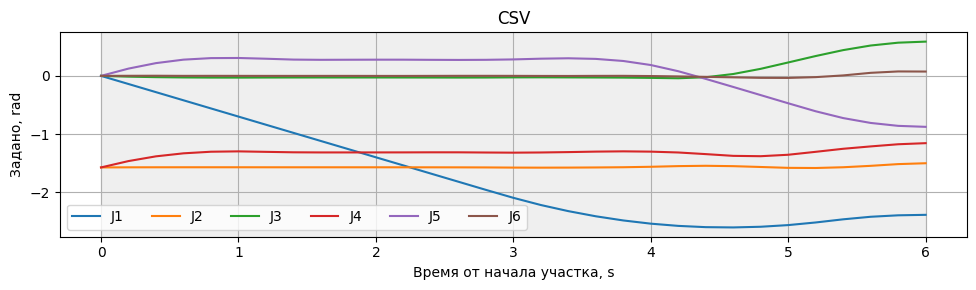

In [10]:
prepared = None
if outstanding():
    raise RuntimeError("Сначала дождитесь завершения подвода")
if loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
    raise RuntimeError("Повторите загрузку CSV")
driver = driver_parameters()
if np.max(abs(stationary_pose()-q[0])) > .005:
    raise RuntimeError("Робот не в начале CSV: выполните отдельную ячейку подвода")
prepared = prepare_path(t.copy(), q.copy(), None, None, 0., "CSV")
print(f"Только {len(t)} точек CSV, {t[-1]:.3f} s; скорости/ускорения из файла не используются")

### Выполнить CSV
Поставьте `RUN_MOTION=True`. Подвод не запускается; перед отправкой снова проверяется
начальная неподвижная поза. Каждое разрешение сбрасывается после одной попытки.
При отказе частичная запись остаётся доступна для графиков.

In [11]:
RUN_MOTION = True  # Только позиции/время CSV; отдельный подвод не запускается.
if not RUN_MOTION:
    print("RUN_MOTION=False: CSV не отправлен")
else:
    RUN_MOTION = False
    if outstanding():
        raise RuntimeError("Предыдущая цель ещё активна/неизвестна: сначала cancel()")
    analysis_run_id = None
    run = {}
    execute_path(prepared, run)

{'status': 4, 'error_code': 0, 'action_roundtrip_s': 9.003703351001604}
Серверные timestamps: {'receipt_stamp_ns': 1793290317438879897, 'nominal_start_stamp_ns': 1793290320438107911, 'first_command_stamp_ns': 1793290320440420593, 'nominal_start_final': True}
В памяти 751 goal-feedback измерений. Графики доступны и после отказа.


## 5. Задание, измерение и ошибка
График показывает только последний CSV-запуск, без отдельной цели подвода.
Все данные относятся к CSV; при отказе показана доступная часть. Ошибка = **измерено − задано**, без сдвига времени для «улучшения» графика.
Задание взято из feedback драйвера в тот же момент времени, что и измерение.
При упреждении это исходный эталон CSV(t), а не опережающая ServoJ-команда CSV(t+advance).
Ось X — **полный Unix timestamp в секундах**, без скрытого offset.
Для CSV используется серверный `nominal_start_stamp_ns + t`; для обеих кривых feedback
используется один `header.stamp`. Timestamp получения цели/старта берётся из
`trajectory_timing` с UUID именно этой цели, не из времени отправки ноутбуком.
`header.stamp` — получение результата чтения,
**не время энкодера**. Из графиков нельзя отдельно определить чистую сетевую задержку.
`status=4, code=0` означает успешное завершение; частичный график не означает успех.

Получение цели UTC: 2026-10-29 16:11:57.438879897+00:00
Номинальный старт UTC: 2026-10-29 16:12:00.438107911+00:00
Серверный t0 − запрошенный header.stamp, ns: 0
Старт − формирование сообщения, s: 3.0
Старт − получение, s: 2.9992280140000003
Первая ServoJ − получение, s: 3.001540696
Расхождение ROS timestamp и steady elapsed, max µs: 0.27
max |feedback desired − CSV(t)|, rad: 6.988649658978829e-10
Доставка feedback median/max, ms: 1.09731 2.637156
Упреждение команд, ms: 0.0


,joint,RMSE_rad,max_abs_rad
0,shoulder_joint,2.952154e-06,0.000056
1,upper_arm_joint,2.174351e-07,0.000004
2,forearm_joint,8.228147e-07,0.000006
3,wrist_1_joint,1.738799e-06,0.000044
4,wrist_2_joint,2.264064e-06,0.000050
5,wrist_3_joint,2.315569e-07,0.000003


Записано 751 измерений; status=4, code=0, Reached measured endpoint after nominal duration
Показан интервал 1793290320.440…1793290326.432 s; полный CSV = 6.000 s
Интервал измерений median/max, ms: 7.999420166015625 8.128881454467773


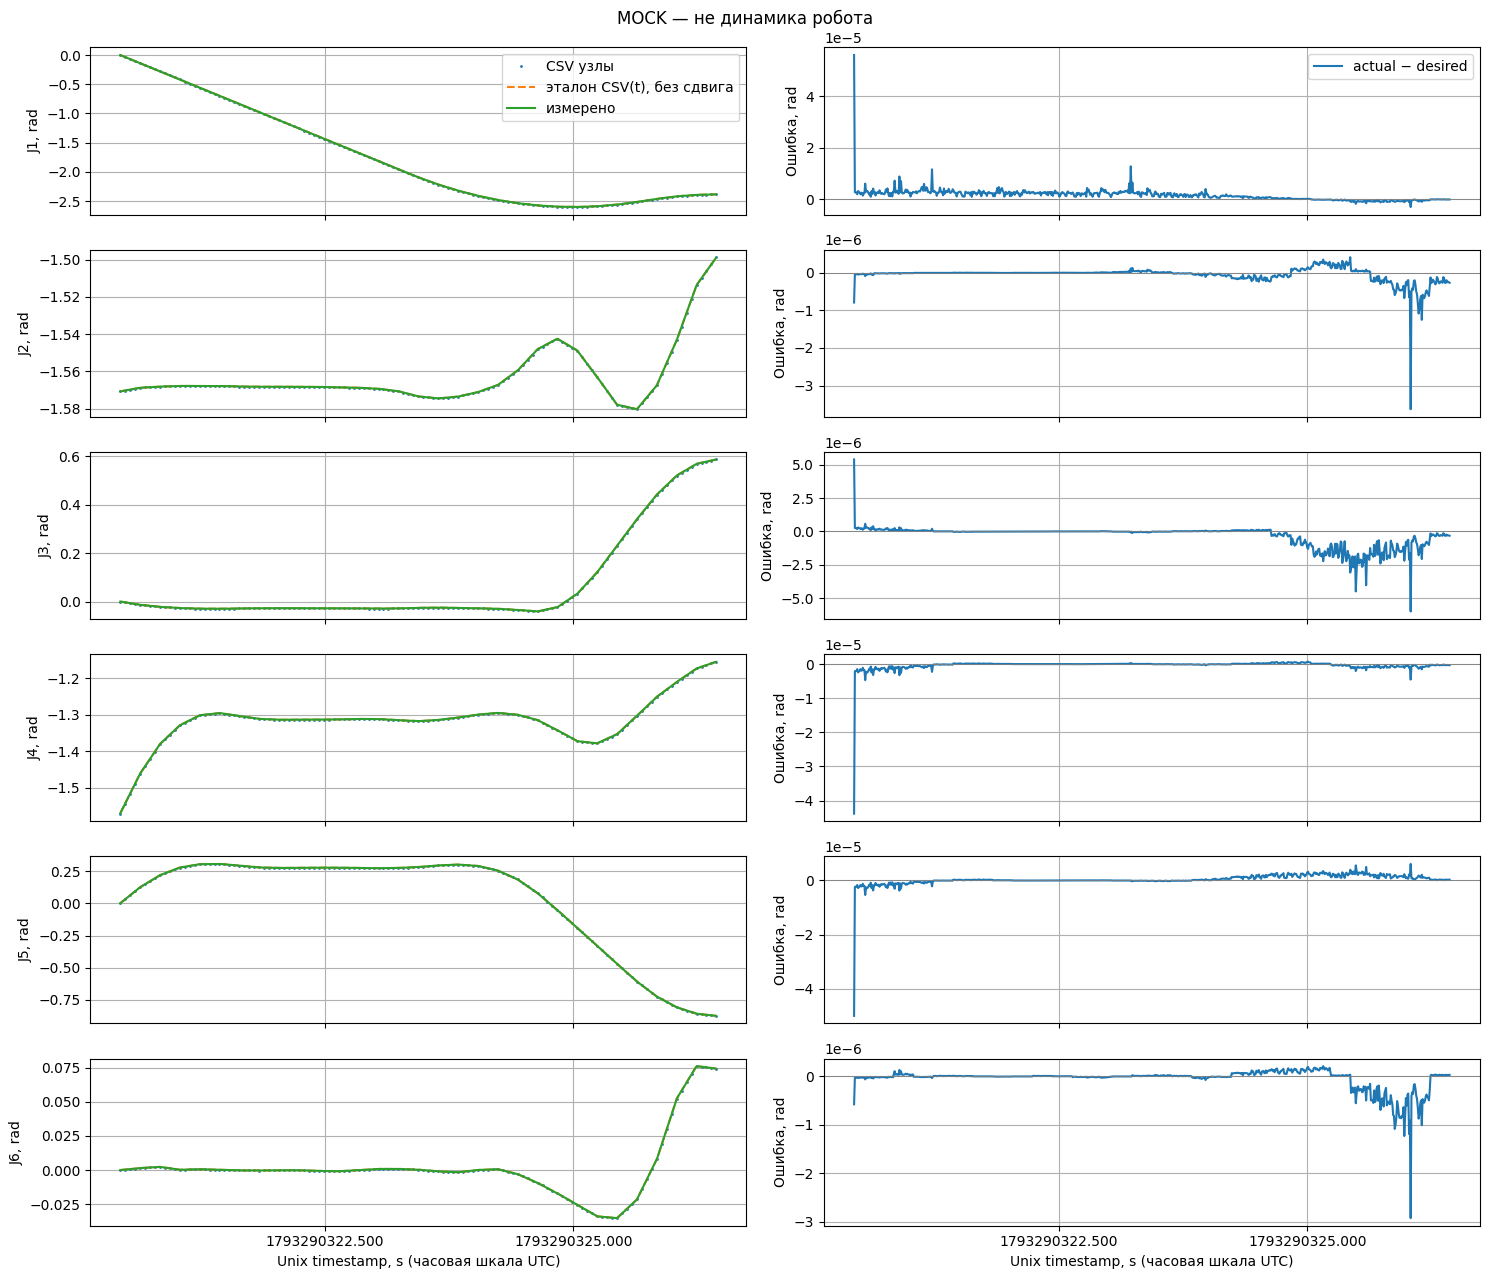

In [12]:
if not globals().get("run", {}).get("rows"):
    raise RuntimeError("Нет feedback текущего запуска; сначала выполните отправку")
raw = pd.DataFrame(run["rows"], columns=["stamp_ns", "receive_ns", "elapsed_s",
    *[f"desired_J{j}" for j in range(1, 7)], *[f"actual_J{j}" for j in range(1, 7)]])
if np.any(np.diff(raw.stamp_ns.to_numpy(dtype=np.int64)) <= 0):
    raise RuntimeError("Временные метки измерений не возрастают")
# elapsed_s вычислен драйвером по steady clock для момента получения измерения.
raw["t_csv_s"] = raw.elapsed_s-run["lead"]
selected = raw[(raw.t_csv_s >= 0) & (raw.t_csv_s <= run["csv_t"][-1])].copy()
# Даже при раннем отказе покажем доступную часть записи.
if len(selected) < 2:
    print("Мало измерений: показаны все доступные данные")
    selected = raw.copy()
relative_t = selected.t_csv_s.to_numpy()
timing = run.get("timing")
if not timing or not timing["nominal_start_final"]:
    raise RuntimeError("Нет подтверждённого серверного t0 для этой цели. Нужен новый запуск с trajectory_timing")
nominal_start_ns = timing["nominal_start_stamp_ns"]
x = selected.stamp_ns.to_numpy(dtype=np.int64)*1e-9
csv_stamp_ns = nominal_start_ns + np.rint((run["csv_t"]+run["lead"])*1e9).astype(np.int64)
csv_x = csv_stamp_ns*1e-9
raw["unix_s"] = raw.stamp_ns.to_numpy(dtype=np.int64)*1e-9
raw["stamp_utc"] = pd.to_datetime(raw.stamp_ns, unit="ns", utc=True).astype(str)
print("Получение цели UTC:", pd.to_datetime(timing["receipt_stamp_ns"], unit="ns", utc=True))
print("Номинальный старт UTC:", pd.to_datetime(nominal_start_ns, unit="ns", utc=True))
if run.get("requested_start_stamp_ns"):
    print("Серверный t0 − запрошенный header.stamp, ns:", nominal_start_ns-run["requested_start_stamp_ns"])
    print("Старт − формирование сообщения, s:", (nominal_start_ns-run["request_stamp_ns"])*1e-9)
print("Старт − получение, s:", (nominal_start_ns-timing["receipt_stamp_ns"])*1e-9)
print("Первая ServoJ − получение, s:", (timing["first_command_stamp_ns"]-timing["receipt_stamp_ns"])*1e-9)
clock_residual_ns = raw.stamp_ns.to_numpy(dtype=np.int64)-nominal_start_ns-np.rint(raw.elapsed_s.to_numpy()*1e9).astype(np.int64)
print("Расхождение ROS timestamp и steady elapsed, max µs:", np.max(abs(clock_residual_ns))*.001)
actual = selected[[f"actual_J{j}" for j in range(1, 7)]].to_numpy()
desired = selected[[f"desired_J{j}" for j in range(1, 7)]].to_numpy()
if not np.isfinite(np.c_[x, actual, desired]).all():
    raise RuntimeError("В feedback есть NaN/Inf")
# Проверяем время эталона отдельно от фактического слежения, не сдвигая измерения.
if run["interpolation"] == "linear":
    csv_reference = np.column_stack([np.interp(relative_t, run["csv_t"], run["csv_q"][:, j]) for j in range(6)])
    print("max |feedback desired − CSV(t)|, rad:", np.max(abs(desired-csv_reference)))
print("Доставка feedback median/max, ms:",
      np.median((raw.receive_ns-raw.stamp_ns)*1e-6), np.max((raw.receive_ns-raw.stamp_ns)*1e-6))
print("Упреждение команд, ms:", run["driver"].get("trajectory_advance_ms", 0.))
error = actual-desired  # Знак указан явно; ROS error.positions имеет обратный знак.
metrics = pd.DataFrame({"joint": run["joints"], "RMSE_rad": np.sqrt(np.mean(error**2, axis=0)),
                        "max_abs_rad": np.max(abs(error), axis=0)})
display(metrics)
print(f"Записано {len(raw)} измерений; status={run['status']}, code={run['error_code']}, {run['error_string']}")
print(f"Показан интервал {x[0]:.3f}…{x[-1]:.3f} s; полный CSV = {run['csv_t'][-1]:.3f} s")
if len(x) > 1:
    print("Интервал измерений median/max, ms:", np.median(np.diff(x))*1000, np.max(np.diff(x))*1000)
tracking_fig, axes = plt.subplots(6, 2, figsize=(15, 13), sharex=True)
for j in range(6):
    axes[j, 0].plot(csv_x, run["csv_q"][:, j], ".", ms=2, label="CSV узлы")
    axes[j, 0].plot(x, desired[:, j], "--", label="эталон CSV(t), без сдвига")
    axes[j, 0].plot(x, actual[:, j], label="измерено")
    axes[j, 1].plot(x, error[:, j], label="actual − desired")
    axes[j, 1].axhline(0, color="gray", lw=.6)
    axes[j, 0].set_ylabel(f"J{j+1}, rad"); axes[j, 1].set_ylabel("Ошибка, rad")
    for ax in axes[j]: ax.grid(True)
for ax in axes[0]: ax.legend()
from matplotlib.ticker import FuncFormatter, MaxNLocator
for ax in axes[-1]:
    ax.set_xlabel("Unix timestamp, s (часовая шкала UTC)")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.3f}"))
tracking_fig.suptitle("MOCK — не динамика робота" if run["driver"]["use_mock_hardware"] else "Реальные измерения")
plt.tight_layout()
analysis_run_id = run["run_id"]

## 6. Сохранить при необходимости и отключиться
`SAVE=True` сохраняет feedback, отправленную траекторию, метрики, параметры и PNG.

In [13]:
SAVE = False
if SAVE:
    if (not globals().get("run") or "run_id" not in run
            or globals().get("analysis_run_id") != run["run_id"]):
        raise RuntimeError("Сначала выполните анализ именно текущего опыта; старые метрики не сохраняются")
    import json
    from datetime import datetime, timezone
    out = ROOT / "results" / ("left_ethernet_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
    out.mkdir(parents=True, exist_ok=False)
    raw.to_csv(out / "feedback.csv", index=False)
    metrics.to_csv(out / "metrics.csv", index=False)
    pd.DataFrame(np.c_[run["t"], run["q"]], columns=["t",
        *[f"q{j}_rad" for j in range(1, 7)]]).to_csv(out / "sent_trajectory.csv", index=False)
    (out / "run.json").write_text(json.dumps({k: run[k] for k in
        ("source", "scale", "lead", "run_id", "request_stamp_ns", "requested_start_stamp_ns", "start_delay_s", "interpolation", "status", "error_code", "error_string", "driver", "goal_uuid", "timing")}, indent=2), encoding="utf-8")
    pd.DataFrame({"stamp_ns": csv_stamp_ns, "stamp_utc": pd.to_datetime(csv_stamp_ns, unit="ns", utc=True),
                  **{f"q{j+1}_rad": run["csv_q"][:, j] for j in range(6)}}).to_csv(out / "scheduled_trajectory.csv", index=False)
    tracking_fig.savefig(out / "tracking.png", dpi=150)
    print(out)

In [14]:
if outstanding():
    raise RuntimeError("Цель ещё активна/неизвестна: выполните cancel() и дождитесь terminal status")
executor.shutdown(timeout_sec=2)
client.destroy()
node.destroy_node()
ctx.shutdown()
node = None
print("ROS-клиент закрыт; питание робота не изменялось")

ROS-клиент закрыт; питание робота не изменялось
